In [33]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
import pandas as pd

df = pd.read_excel("/content/drive/MyDrive/FinSightAssessment/Working Files /Cleaned DATA /Cleaned Data.xlsx")

In [35]:
df.describe()

,Date_of_Birth,Age,Account_Open_Date,Customer_Tenure_Years,Savings_Balance,Monthly_Deposit_Avg,Monthly_Withdrawal_Avg,Net_Monthly_Flow,Loan_Amount,Loan_Tenure_Months,Monthly_Repayment_Amount,Loan_Start_Date,Outstanding_Loan_Balance,Last_Login_Date,Monthly_Transaction_Count,KYC_Last_Updated,FD_Amount,Number_of_Products
count,500,500.000000,500,500.000000,5.000000e+02,500.000000,500.000000,500.000000,2.180000e+02,218.00000,218.000000,217,2.180000e+02,329,500.000000,375,1.450000e+02,500.000000
mean,1986-12-12 14:18:14.400000,36.560000,2019-07-26 18:29:13.919999744,4.434800,7.691986e+05,38122.890300,22037.252620,16085.637680,1.427705e+06,34.12844,66446.899312,2021-11-10 15:35:40.092165888,7.699788e+05,2023-09-20 02:50:41.945288704,12.786000,2022-04-15 21:49:26.400000,1.074669e+06,2.486000
min,1970-01-18 00:00:00,21.000000,2015-01-14 00:00:00,0.000000,5.945010e+03,194.790000,100.990000,30.870000,5.430853e+04,12.00000,1008.140000,2016-10-22 00:00:00,1.625884e+04,2023-06-01 00:00:00,0.000000,2020-01-07 00:00:00,1.132178e+05,1.000000
25%,1978-06-15 18:00:00,28.000000,2017-02-13 00:00:00,2.200000,1.207980e+05,5758.960000,3230.255000,1953.555000,7.096586e+05,12.00000,20592.450000,2020-08-30 00:00:00,2.339746e+05,2023-08-01 00:00:00,3.000000,2021-04-22 12:00:00,6.316680e+05,2.000000
50%,1987-01-31 00:00:00,36.000000,2019-09-05 00:00:00,4.300000,4.495058e+05,17858.540000,9593.690000,6044.870000,1.431862e+06,36.00000,47278.575000,2022-07-03 00:00:00,6.712288e+05,2023-09-18 00:00:00,9.000000,2022-04-14 00:00:00,1.101161e+06,2.000000
75%,1995-05-28 00:00:00,45.000000,2021-10-21 18:00:00,6.900000,7.287117e+05,40721.177500,22889.240000,17196.790000,2.109643e+06,48.00000,82529.862500,2023-06-06 00:00:00,1.191630e+06,2023-11-11 00:00:00,22.000000,2023-05-08 12:00:00,1.501144e+06,3.000000
max,2002-12-29 00:00:00,53.000000,2023-12-30 00:00:00,9.000000,4.916005e+06,347140.120000,230688.560000,196240.990000,2.998363e+06,60.00000,274849.530000,2023-12-31 00:00:00,2.460698e+06,2024-01-01 00:00:00,35.000000,2024-01-01 00:00:00,1.977886e+06,5.000000
std,NaN,9.689074,NaN,2.631966,1.084648e+06,58017.651982,34962.647569,26953.742972,8.453553e+05,17.48474,64127.945546,NaN,5.917247e+05,NaN,10.862236,NaN,5.348230e+05,0.929264


###Q1 - Savings & Customer Behaviour

####Q1.1

In [36]:
import pandas as pd


# 1. Average savings by Customer Segment, Province, and Urban/Rural
print('--- Savings by Customer Segment ---')
print(
    df.groupby('Customer_Segment')['Savings_Balance'].agg(
        ['mean', 'median', 'count', 'sum']
    )
)

print('\n--- Savings by Province ---')
print(
    df.groupby('Province')['Savings_Balance'].agg(
        ['mean', 'median', 'count', 'sum']
    )
)

print('\n--- Savings by Urban/Rural Classification ---')
print(
    df.groupby('Urban_Rural')['Savings_Balance'].agg(
        ['mean', 'median', 'count', 'sum']
    )
)

# 2. Age Group Analysis (Bands: 21-32, 33-42, 43-53)
bins = [20, 32, 42, 53]
labels = [
    'Young Adults (21–32)',
    'Mid-Adults (33–42)',
    'Established Adults (43–53)',
]
df['Custom_Age_Band'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

print('\n--- Savings by Custom Age Band ---')
print(
    df.groupby('Custom_Age_Band', observed=False)['Savings_Balance'].agg(
        ['count', 'mean', 'median', 'sum']
    )
)

# 3. Savings Growth vs Draining (Net Monthly Flow)
df['Savings_Trend'] = df['Net_Monthly_Flow'].apply(
    lambda x: 'Growing (>0)'
    if x > 0
    else ('Draining (<0)' if x < 0 else 'Neutral (=0)')
)
print('\n--- Monthly Savings Trend Breakdown ---')
print(df['Savings_Trend'].value_counts(normalize=True) * 100)
print(df['Savings_Trend'].value_counts())

--- Savings by Customer Segment ---
                          mean       median  count           sum
Customer_Segment                                                
Premium           2.642320e+06  2504759.735     92  2.430935e+08
Regular           4.236344e+05   449505.785    316  1.338685e+08
Starter           8.301511e+04    85217.430     92  7.637390e+06

--- Savings by Province ---
                        mean      median  count           sum
Province                                                     
Central        720674.288830  430134.970     47  3.387169e+07
Eastern        956406.192600  555805.010     50  4.782031e+07
North Western  768462.474364  532220.840     55  4.226544e+07
Northern       665874.560169  398756.140     59  3.928660e+07
Sabaragamuwa   903220.093929  409666.595     56  5.058033e+07
Southern       658411.418000  378636.025     80  5.267291e+07
Uva            630638.462000  416563.695     50  3.153192e+07
Western        840486.585194  444780.780    103  8.6

In [37]:



# Filter out rows where savings were imputed
df_filtered = df[df['Savings_Imputed'] != 'Yes'].copy()

# 1. Average savings by Customer Segment, Province, and Urban/Rural
print('--- Savings by Customer Segment (Non-Imputed) ---')
print(
    df_filtered.groupby('Customer_Segment')['Savings_Balance'].agg(
        ['mean', 'median', 'count', 'sum']
    )
)

print('\n--- Savings by Province (Non-Imputed) ---')
print(
    df_filtered.groupby('Province')['Savings_Balance'].agg(
        ['mean', 'median', 'count', 'sum']
    )
)

print('\n--- Savings by Urban/Rural Classification (Non-Imputed) ---')
print(
    df_filtered.groupby('Urban_Rural')['Savings_Balance'].agg(
        ['mean', 'median', 'count', 'sum']
    )
)

# 2. Age Group Analysis (Bands: 21-32, 33-42, 43-53)
bins = [20, 32, 42, 53]
labels = [
    'Young Adults (21–32)',
    'Mid-Adults (33–42)',
    'Established Adults (43–53)',
]
df_filtered['Custom_Age_Band'] = pd.cut(
    df_filtered['Age'], bins=bins, labels=labels, right=True
)

print('\n--- Savings by Custom Age Band (Non-Imputed) ---')
print(
    df_filtered.groupby('Custom_Age_Band', observed=False)['Savings_Balance'].agg(
        ['count', 'mean', 'median', 'sum']
    )
)

# 3. Savings Growth vs Draining (Net Monthly Flow)
df_filtered['Savings_Trend'] = df_filtered['Net_Monthly_Flow'].apply(
    lambda x: 'Growing (>0)'
    if x > 0
    else ('Draining (<0)' if x < 0 else 'Neutral (=0)')
)
print('\n--- Monthly Savings Trend Breakdown (Non-Imputed) ---')
print(df_filtered['Savings_Trend'].value_counts(normalize=True) * 100)
print(df_filtered['Savings_Trend'].value_counts())

--- Savings by Customer Segment (Non-Imputed) ---
                          mean       median  count           sum
Customer_Segment                                                
Premium           2.641704e+06  2491412.250     91  2.403951e+08
Regular           4.236598e+05   446538.920    308  1.304872e+08
Starter           8.296617e+04    86819.175     90  7.466956e+06

--- Savings by Province (Non-Imputed) ---
                        mean      median  count          sum
Province                                                    
Central        738830.900889  430134.970     45  33247390.54
Eastern        965043.833878  562847.610     49  47287147.86
North Western  785793.526226  532220.840     53  41647056.89
Northern       630830.748793  398645.900     58  36588183.43
Sabaragamuwa   925221.223333  409666.595     54  49961946.06
Southern       658411.418000  378636.025     80  52672913.44
Uva            630638.462000  416563.695     50  31531923.10
Western        854126.554700  436

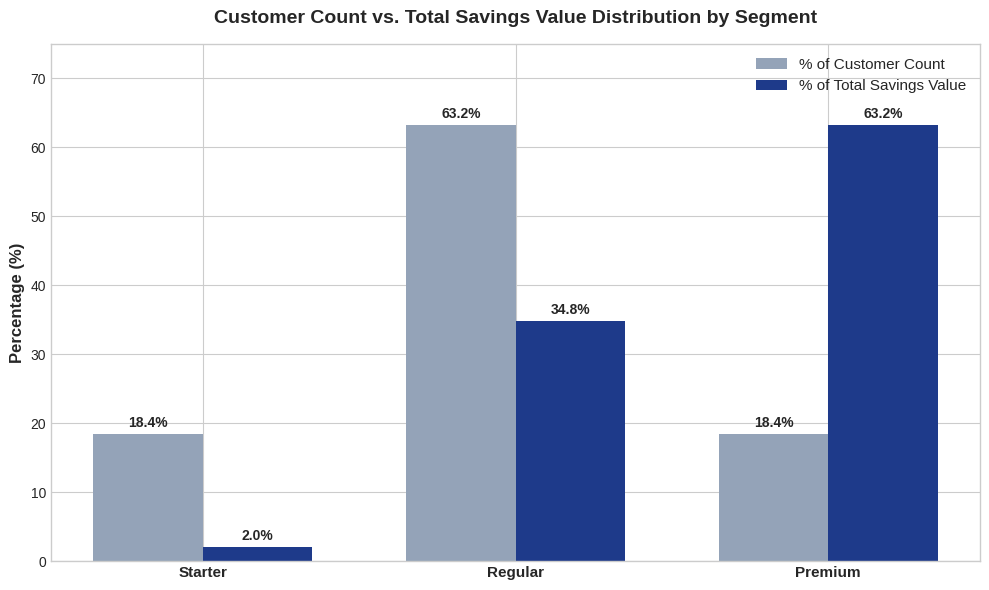

In [38]:
import matplotlib.pyplot as plt
import numpy as np

segment_summary = df.groupby('Customer_Segment').agg(
    Customer_Count=('Customer_ID', 'count'),
    Total_Savings=('Savings_Balance', 'sum')
).reindex(['Starter', 'Regular', 'Premium']).reset_index()

# 2. Calculate percentages
total_customers = segment_summary['Customer_Count'].sum()
total_savings = segment_summary['Total_Savings'].sum()

segment_summary['Pct_Count'] = (segment_summary['Customer_Count'] / total_customers) * 100
segment_summary['Pct_Savings'] = (segment_summary['Total_Savings'] / total_savings) * 100

# 3. Plotting Side-by-Side Comparison Chart
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(segment_summary['Customer_Segment']))
width = 0.35

rects1 = ax.bar(x - width/2, segment_summary['Pct_Count'], width, label='% of Customer Count', color='#94a3b8')
rects2 = ax.bar(x + width/2, segment_summary['Pct_Savings'], width, label='% of Total Savings Value', color='#1e3a8a')

# Formatting labels and title
ax.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold')
ax.set_title('Customer Count vs. Total Savings Value Distribution by Segment', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(segment_summary['Customer_Segment'], fontsize=11, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0, 75)

# Add data labels
for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

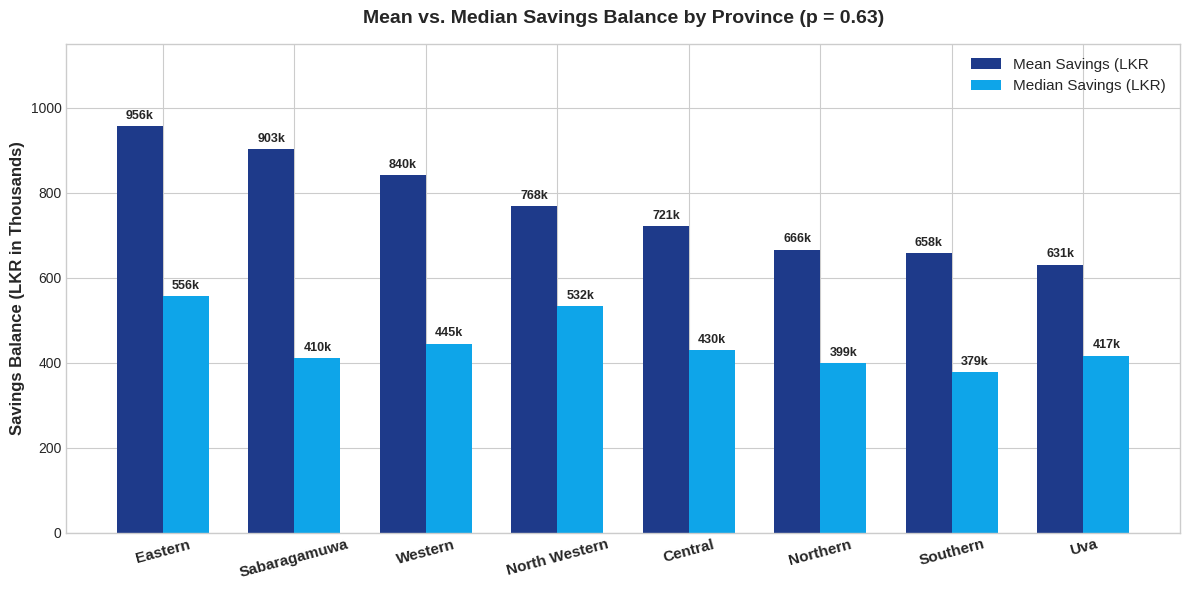

In [39]:


prov_summary = df.groupby('Province')['Savings_Balance'].agg(
    Mean=('mean'),
    Median=('median')
).reset_index()

prov_summary['Mean_k'] = prov_summary['Mean'] / 1000
prov_summary['Median_k'] = prov_summary['Median'] / 1000

# Sort by Mean descending for clear visual structure
prov_summary = prov_summary.sort_values(by='Mean_k', ascending=False)

# 2. Plotting Mean vs. Median Comparison Chart
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(prov_summary))
width = 0.35

rects1 = ax.bar(x - width/2, prov_summary['Mean_k'], width, label='Mean Savings (LKR', color='#1e3a8a')
rects2 = ax.bar(x + width/2, prov_summary['Median_k'], width, label='Median Savings (LKR)', color='#0ea5e9')

# Formatting
ax.set_ylabel('Savings Balance (LKR in Thousands)', fontsize=12, fontweight='bold')
ax.set_title('Mean vs. Median Savings Balance by Province (p = 0.63)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(prov_summary['Province'], fontsize=11, fontweight='bold', rotation=15)
ax.legend(fontsize=11)
ax.set_ylim(0, 1150)

# Add data labels
for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.0f}k',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.0f}k',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

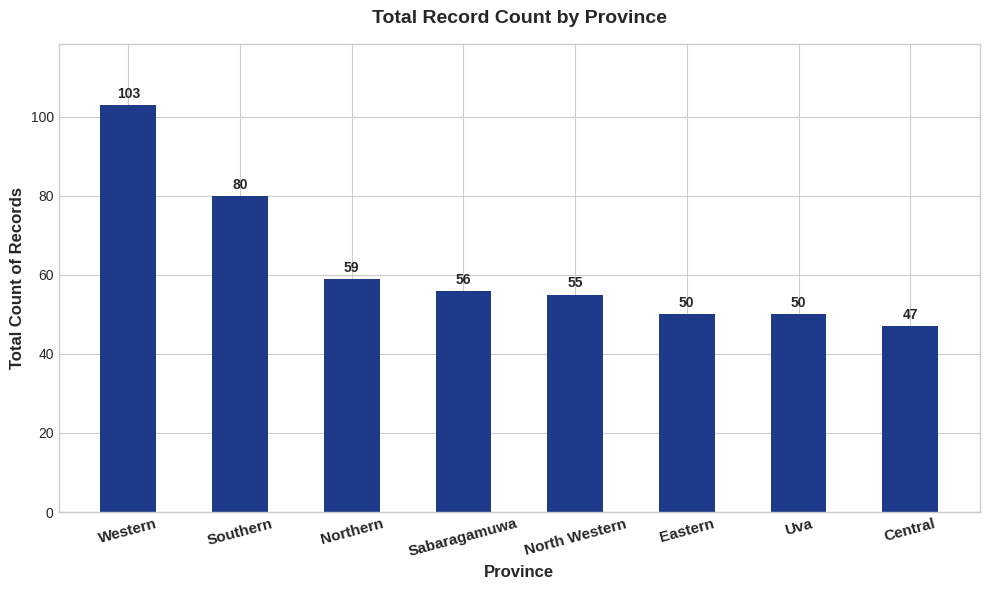

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Group by Province to get exact raw counts
prov_counts = df.groupby('Province')['Savings_Balance'].count().reset_index(name='Raw_Count')

# Sort descending by raw count for a structured visual
prov_counts = prov_counts.sort_values(by='Raw_Count', ascending=False)

# 2. Plotting Exact Raw Counts
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    prov_counts['Province'],
    prov_counts['Raw_Count'],
    color='#1e3a8a',
    width=0.5
)

# Formatting
ax.set_ylabel('Total Count of Records', fontsize=12, fontweight='bold')
ax.set_xlabel('Province', fontsize=12, fontweight='bold')
ax.set_title('Total Record Count by Province', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(range(len(prov_counts)))
ax.set_xticklabels(prov_counts['Province'], fontsize=11, fontweight='bold', rotation=15)

# Add head room on Y axis for data labels
ax.set_ylim(0, prov_counts['Raw_Count'].max() * 1.15)

# Add exact raw number labels on top of each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{int(height):,}',  # Shows exact raw count (e.g. 1,250)
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

####Q1.2

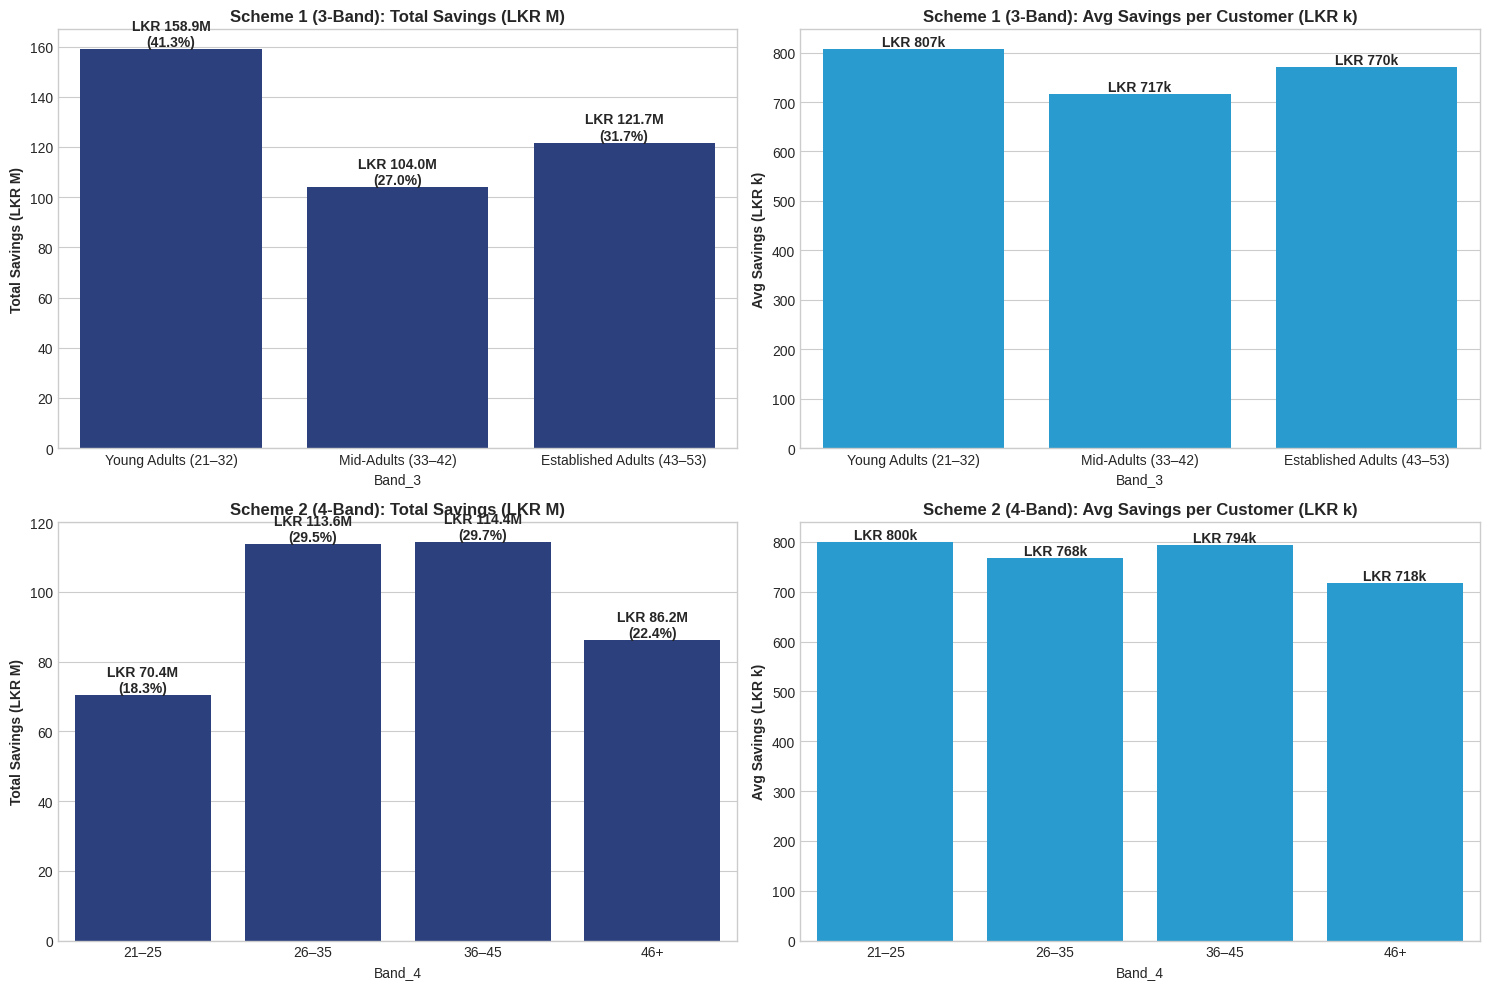

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# Define Bandings
def age_band_3(age):
    if 21 <= age <= 32: return 'Young Adults (21–32)'
    elif 33 <= age <= 42: return 'Mid-Adults (33–42)'
    elif 43 <= age <= 53: return 'Established Adults (43–53)'

def age_band_4(age):
    if 21 <= age <= 25: return '21–25'
    elif 26 <= age <= 35: return '26–35'
    elif 36 <= age <= 45: return '36–45'
    elif age >= 46: return '46+'

df['Band_3'] = df['Age'].apply(age_band_3)
df['Band_4'] = df['Age'].apply(age_band_4)

# Aggregate
s1 = df.groupby('Band_3')['Savings_Balance'].agg(Total='sum', Mean='mean').reindex(
    ['Young Adults (21–32)', 'Mid-Adults (33–42)', 'Established Adults (43–53)']).reset_index()
s2 = df.groupby('Band_4')['Savings_Balance'].agg(Total='sum', Mean='mean').reindex(
    ['21–25', '26–35', '36–45', '46+']).reset_index()

s1['Total_M'], s1['Mean_k'] = s1['Total'] / 1e6, s1['Mean'] / 1e3
s2['Total_M'], s2['Mean_k'] = s2['Total'] / 1e6, s2['Mean'] / 1e3

# Plotting Comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
total_savings = df['Savings_Balance'].sum()

# Scheme 1 Plots
sns.barplot(data=s1, x='Band_3', y='Total_M', color='#1e3a8a', ax=axes[0, 0])
axes[0, 0].set_title('Scheme 1 (3-Band): Total Savings (LKR M)', fontweight='bold')
axes[0, 0].set_ylabel('Total Savings (LKR M)', fontweight='bold')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'LKR {p.get_height():.1f}M\n({(p.get_height()*1e6/total_savings)*100:.1f}%)',
                        (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')

sns.barplot(data=s1, x='Band_3', y='Mean_k', color='#0ea5e9', ax=axes[0, 1])
axes[0, 1].set_title('Scheme 1 (3-Band): Avg Savings per Customer (LKR k)', fontweight='bold')
axes[0, 1].set_ylabel('Avg Savings (LKR k)', fontweight='bold')
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f'LKR {p.get_height():.0f}k',
                        (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')

# Scheme 2 Plots
sns.barplot(data=s2, x='Band_4', y='Total_M', color='#1e3a8a', ax=axes[1, 0])
axes[1, 0].set_title('Scheme 2 (4-Band): Total Savings (LKR M)', fontweight='bold')
axes[1, 0].set_ylabel('Total Savings (LKR M)', fontweight='bold')
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f'LKR {p.get_height():.1f}M\n({(p.get_height()*1e6/total_savings)*100:.1f}%)',
                        (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')

sns.barplot(data=s2, x='Band_4', y='Mean_k', color='#0ea5e9', ax=axes[1, 1])
axes[1, 1].set_title('Scheme 2 (4-Band): Avg Savings per Customer (LKR k)', fontweight='bold')
axes[1, 1].set_ylabel('Avg Savings (LKR k)', fontweight='bold')
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f'LKR {p.get_height():.0f}k',
                        (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

####Q1.3

In [42]:
# 3. Savings Growth vs Draining (Net Monthly Flow)
df['Savings_Trend'] = df['Net_Monthly_Flow'].apply(
    lambda x: 'Growing (>0)'
    if x > 0
    else ('Draining (<0)' if x < 0 else 'Neutral (=0)')
)
print('\n--- Monthly Savings Trend Breakdown ---')
print(df['Savings_Trend'].value_counts(normalize=True) * 100)
print(df['Savings_Trend'].value_counts())


--- Monthly Savings Trend Breakdown ---
Savings_Trend
Growing (>0)    100.0
Name: proportion, dtype: float64
Savings_Trend
Growing (>0)    500
Name: count, dtype: int64


In [43]:
import sys
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

df["Is_Premium"] = df.Customer_Segment == "Premium"

# ---------------- PALETTE ----------------
BG, GRID = "#0B132B", "#26334d"
AMBER, MUTED, WHITE = "#F59E0B", "#94A3B8", "#FFFFFF"


def summarise(by):
    """One row per group: customers, Premium accounts, total savings (LKR m), Premium savings (LKR m)."""
    g = df.groupby(by).apply(lambda d: pd.Series({
        "customers": len(d),
        "premium": d.Is_Premium.sum(),
        "total": d.Savings_Balance.sum() / 1e6,
        "premium_sav": d.loc[d.Is_Premium, "Savings_Balance"].sum() / 1e6,
    }), include_groups=False)
    g["avg_k"] = g.total / g.customers * 1000          # average per customer, LKR thousand
    return g.sort_values("total")                       # ascending, so the largest bar is on top


def style_axes(*axes):
    for ax in axes:
        ax.set_facecolor(BG)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.tick_params(colors=MUTED, length=0, labelsize=12)
        ax.xaxis.grid(True, color=GRID, lw=0.8)
        ax.set_axisbelow(True)


def new_figure(title, note, ratios, height):
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, height), facecolor=BG, sharey=True,
                               gridspec_kw={"width_ratios": ratios, "wspace": 0.06})
    style_axes(a, b)
    a.tick_params(axis="y", colors=WHITE, labelsize=13)
    fig.suptitle(title, x=0.01, ha="left", color=WHITE, fontsize=18, fontweight="bold", y=0.99)
    fig.text(0.01, 0.01, note, color=MUTED, fontsize=11)
    fig.subplots_adjust(top=0.86, bottom=0.09, left=0.1, right=0.99)
    return fig, a, b


def headcount_vs_savings(g, level, fname):
    """Left: head count. Right: total savings with average per customer."""
    fig, a, b = new_figure(f"Head count and total savings by {level.lower()}",
                           "Avg = average savings per customer, LKR thousand.", [1, 1], 6.2)
    a.barh(g.index, g.customers, color=MUTED, height=0.62)
    for i, v in enumerate(g.customers):
        a.text(v + g.customers.max() * 0.015, i, f"{int(v)}", va="center", color=WHITE, fontsize=12, fontweight="bold")
    a.set_title("Head count (customers)", loc="left", color=WHITE, fontsize=14, fontweight="bold")
    a.set_xlim(0, g.customers.max() * 1.2)

    b.barh(g.index, g.total, color=AMBER, height=0.62)
    for i, (t, av) in enumerate(zip(g.total, g.avg_k)):
        b.text(t + g.total.max() * 0.015, i, f"{t:.1f}M  (avg {av:,.0f}k)", va="center", color=WHITE, fontsize=12)
    b.set_title("Total savings (LKR million)", loc="left", color=WHITE, fontsize=14, fontweight="bold")
    b.set_xlim(0, g.total.max() * 1.45)
    fig.savefig(fname, dpi=160, facecolor=BG)
    plt.close(fig)


def premium_vs_savings(g, level, fname, height):
    """Left: Premium accounts. Right: total savings split into Premium and all other."""
    fig, a, b = new_figure(f"{level}s with more Premium accounts hold more savings",
                           f"Cleaned data, {len(df)} customers, {len(g)} {level.lower()}s.", [1, 1.7], height)
    a.barh(g.index, g.premium, color=AMBER, height=0.62)
    for i, v in enumerate(g.premium):
        a.text(v + g.premium.max() * 0.02, i, f"{int(v)}", va="center", color=WHITE, fontsize=12, fontweight="bold")
    a.set_title("Premium accounts", loc="left", color=WHITE, fontsize=14, fontweight="bold")
    a.set_xlim(0, g.premium.max() * 1.4)

    b.barh(g.index, g.premium_sav, color=AMBER, height=0.62, label="Premium savings")
    b.barh(g.index, g.total - g.premium_sav, left=g.premium_sav, color=MUTED, height=0.62, label="All other savings")
    for i, (t, p) in enumerate(zip(g.total, g.premium_sav)):
        b.text(t + g.total.max() * 0.012, i, f"{t:.1f}M  ({p / t:.0%} Premium)", va="center", color=WHITE, fontsize=12)
    b.set_title(f"Total savings by {level.lower()} (LKR million)", loc="left", color=WHITE, fontsize=14, fontweight="bold")
    b.set_xlim(0, g.total.max() * 1.45)
    b.legend(loc="lower right", frameon=False, fontsize=12, labelcolor=MUTED)
    fig.savefig(fname, dpi=160, facecolor=BG)
    plt.close(fig)


prov = summarise("Province")
dist = summarise("District")
print(prov.round(1).to_string())

headcount_vs_savings(prov, "Province", "headcount_savings_by_province.png")
premium_vs_savings(prov, "Province", "premium_by_province.png", 6.4)
premium_vs_savings(dist, "District", "premium_by_district.png", 6.8)
print("Saved 3 charts")

               customers  premium  total  premium_sav  avg_k
Province                                                    
Uva                 50.0      7.0   31.5         16.0  630.6
Central             47.0     10.0   33.9         21.1  720.7
Northern            59.0     10.0   39.3         21.0  665.9
North Western       55.0      9.0   42.3         24.6  768.5
Eastern             50.0     13.0   47.8         33.0  956.4
Sabaragamuwa        56.0     12.0   50.6         37.2  903.2
Southern            80.0     12.0   52.7         28.4  658.4
Western            103.0     19.0   86.6         61.7  840.5
Saved 3 charts


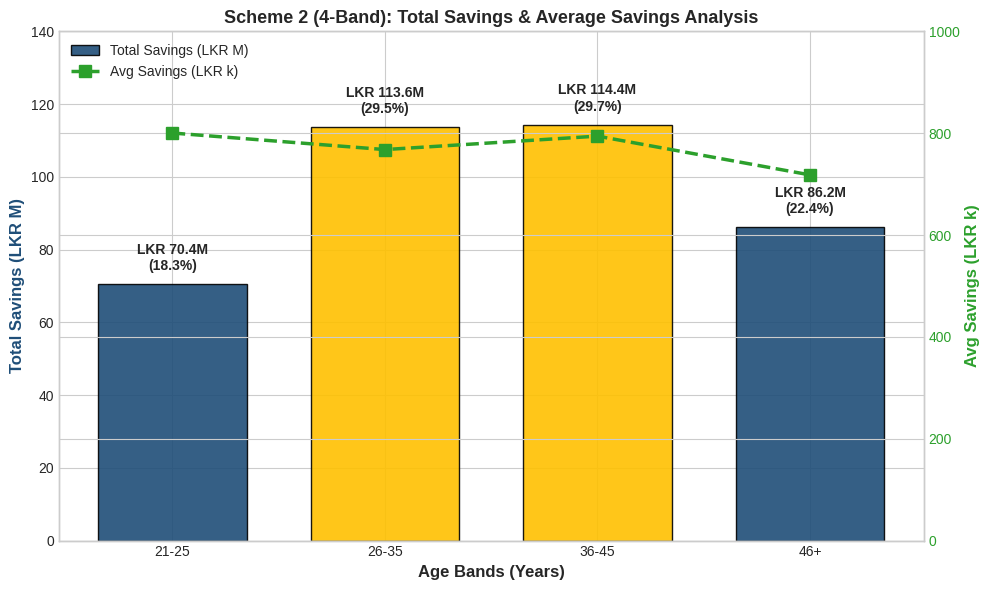

In [44]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd


# 2. Define 4-band age grouping (21-25, 26-35, 36-45, 46+)
bins = [20, 25, 35, 45, 60]
labels = ['21-25', '26-35', '36-45', '46+']
df['Age_Band_4'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

# 3. Aggregate data
summary = (
    df.groupby('Age_Band_4', observed=False)['Savings_Balance']
    .agg(['sum', 'mean', 'count'])
    .reset_index()
)
summary['pct_total'] = (summary['sum'] / summary['sum'].sum()) * 100
summary.columns = [
    'Age_Band',
    'Total_Savings',
    'Avg_Savings',
    'Customer_Count',
    'Pct_Total',
]
summary['Total_Savings_M'] = summary['Total_Savings'] / 1e6
summary['Avg_Savings_k'] = summary['Avg_Savings'] / 1e3

# 4. Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

bar_colors = ['#1f4e78', '#ffc000', '#ffc000', '#1f4e78']
bars1 = ax1.bar(
    summary['Age_Band'],
    summary['Total_Savings_M'],
    color=bar_colors,
    edgecolor='black',
    alpha=0.9,
    width=0.7,
    label='Total Savings (LKR M)',
)

ax1.set_title(
    'Scheme 2 (4-Band): Total Savings & Average Savings Analysis',
    fontsize=13,
    fontweight='bold',
)
ax1.set_ylabel(
    'Total Savings (LKR M)',
    fontsize=12,
    color='#1f4e78',
    fontweight='bold',
)
ax1.set_xlabel('Age Bands (Years)', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 140)

for bar, total, pct in zip(
    bars1, summary['Total_Savings_M'], summary['Pct_Total']
):
  ax1.text(
      bar.get_x() + bar.get_width() / 2.,
      bar.get_height() + 3,
      f'LKR {total:.1f}M\n({pct:.1f}%)',
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
  )

# Secondary Axis for Average Savings Dashed Line
ax2 = ax1.twinx()
ax2.plot(
    summary['Age_Band'],
    summary['Avg_Savings_k'],
    color='#2ca02c',
    marker='s',
    linestyle='--',
    linewidth=2.5,
    markersize=8,
    label='Avg Savings (LKR k)',
)
ax2.set_ylabel(
    'Avg Savings (LKR k)', fontsize=12, color='#2ca02c', fontweight='bold'
)
ax2.set_ylim(0, 1000)
ax2.tick_params(axis='y', labelcolor='#2ca02c')

# Combined Legend
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig('savings_and_avg_only.png', dpi=300)
plt.show()

###Q2 Loan Portfolio & Risk


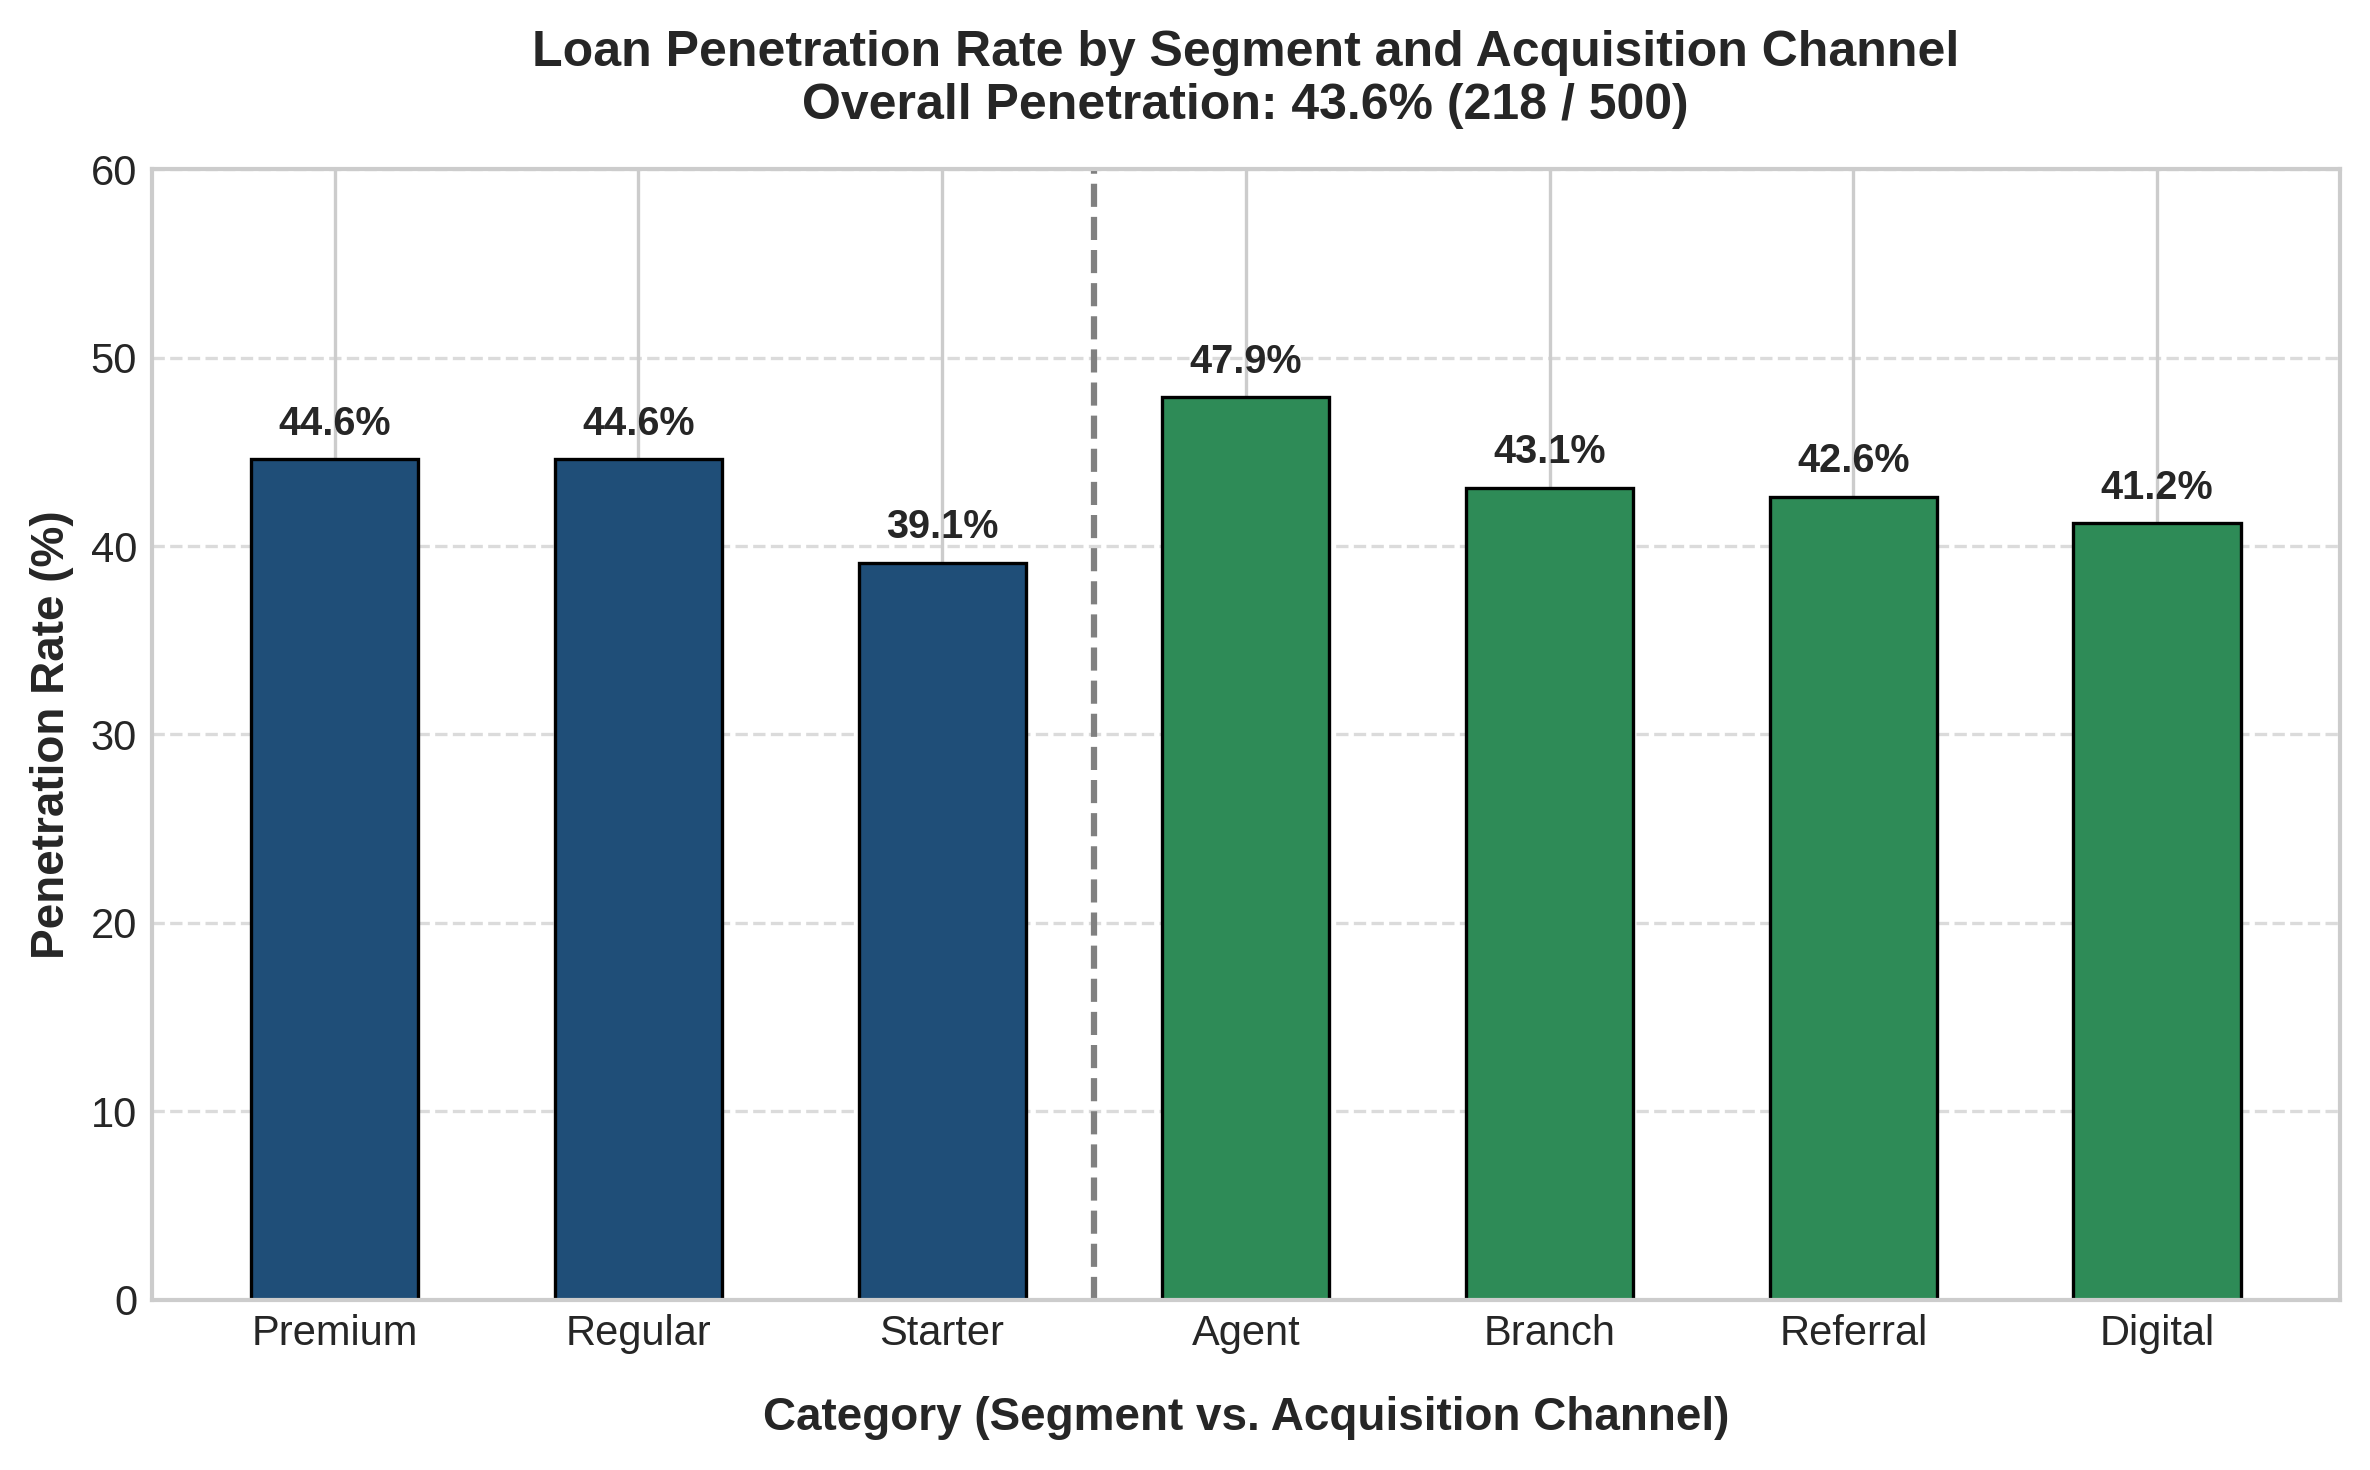

In [45]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

categories = ['Premium', 'Regular', 'Starter', 'Agent', 'Branch', 'Referral', 'Digital']
values = [44.6, 44.6, 39.1, 47.9, 43.1, 42.6, 41.2]
colors = ['#1f4e78', '#1f4e78', '#1f4e78', '#2e8b57', '#2e8b57', '#2e8b57', '#2e8b57']

x = np.arange(len(categories))
bars = ax.bar(x, values, width=0.55, color=colors, edgecolor='black', linewidth=0.8)

# Vertical dividing line
ax.axvline(x=2.5, color='gray', linestyle='--', linewidth=1.5)

# Axis labels & styling
ax.set_ylabel('Penetration Rate (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('Category (Segment vs. Acquisition Channel)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('Loan Penetration Rate by Segment and Acquisition Channel\nOverall Penetration: 43.6% (218 / 500)', fontsize=12, fontweight='bold', pad=12)

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 60)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Bar labels
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

###Q3 - Digital Engagement & Product Holdings

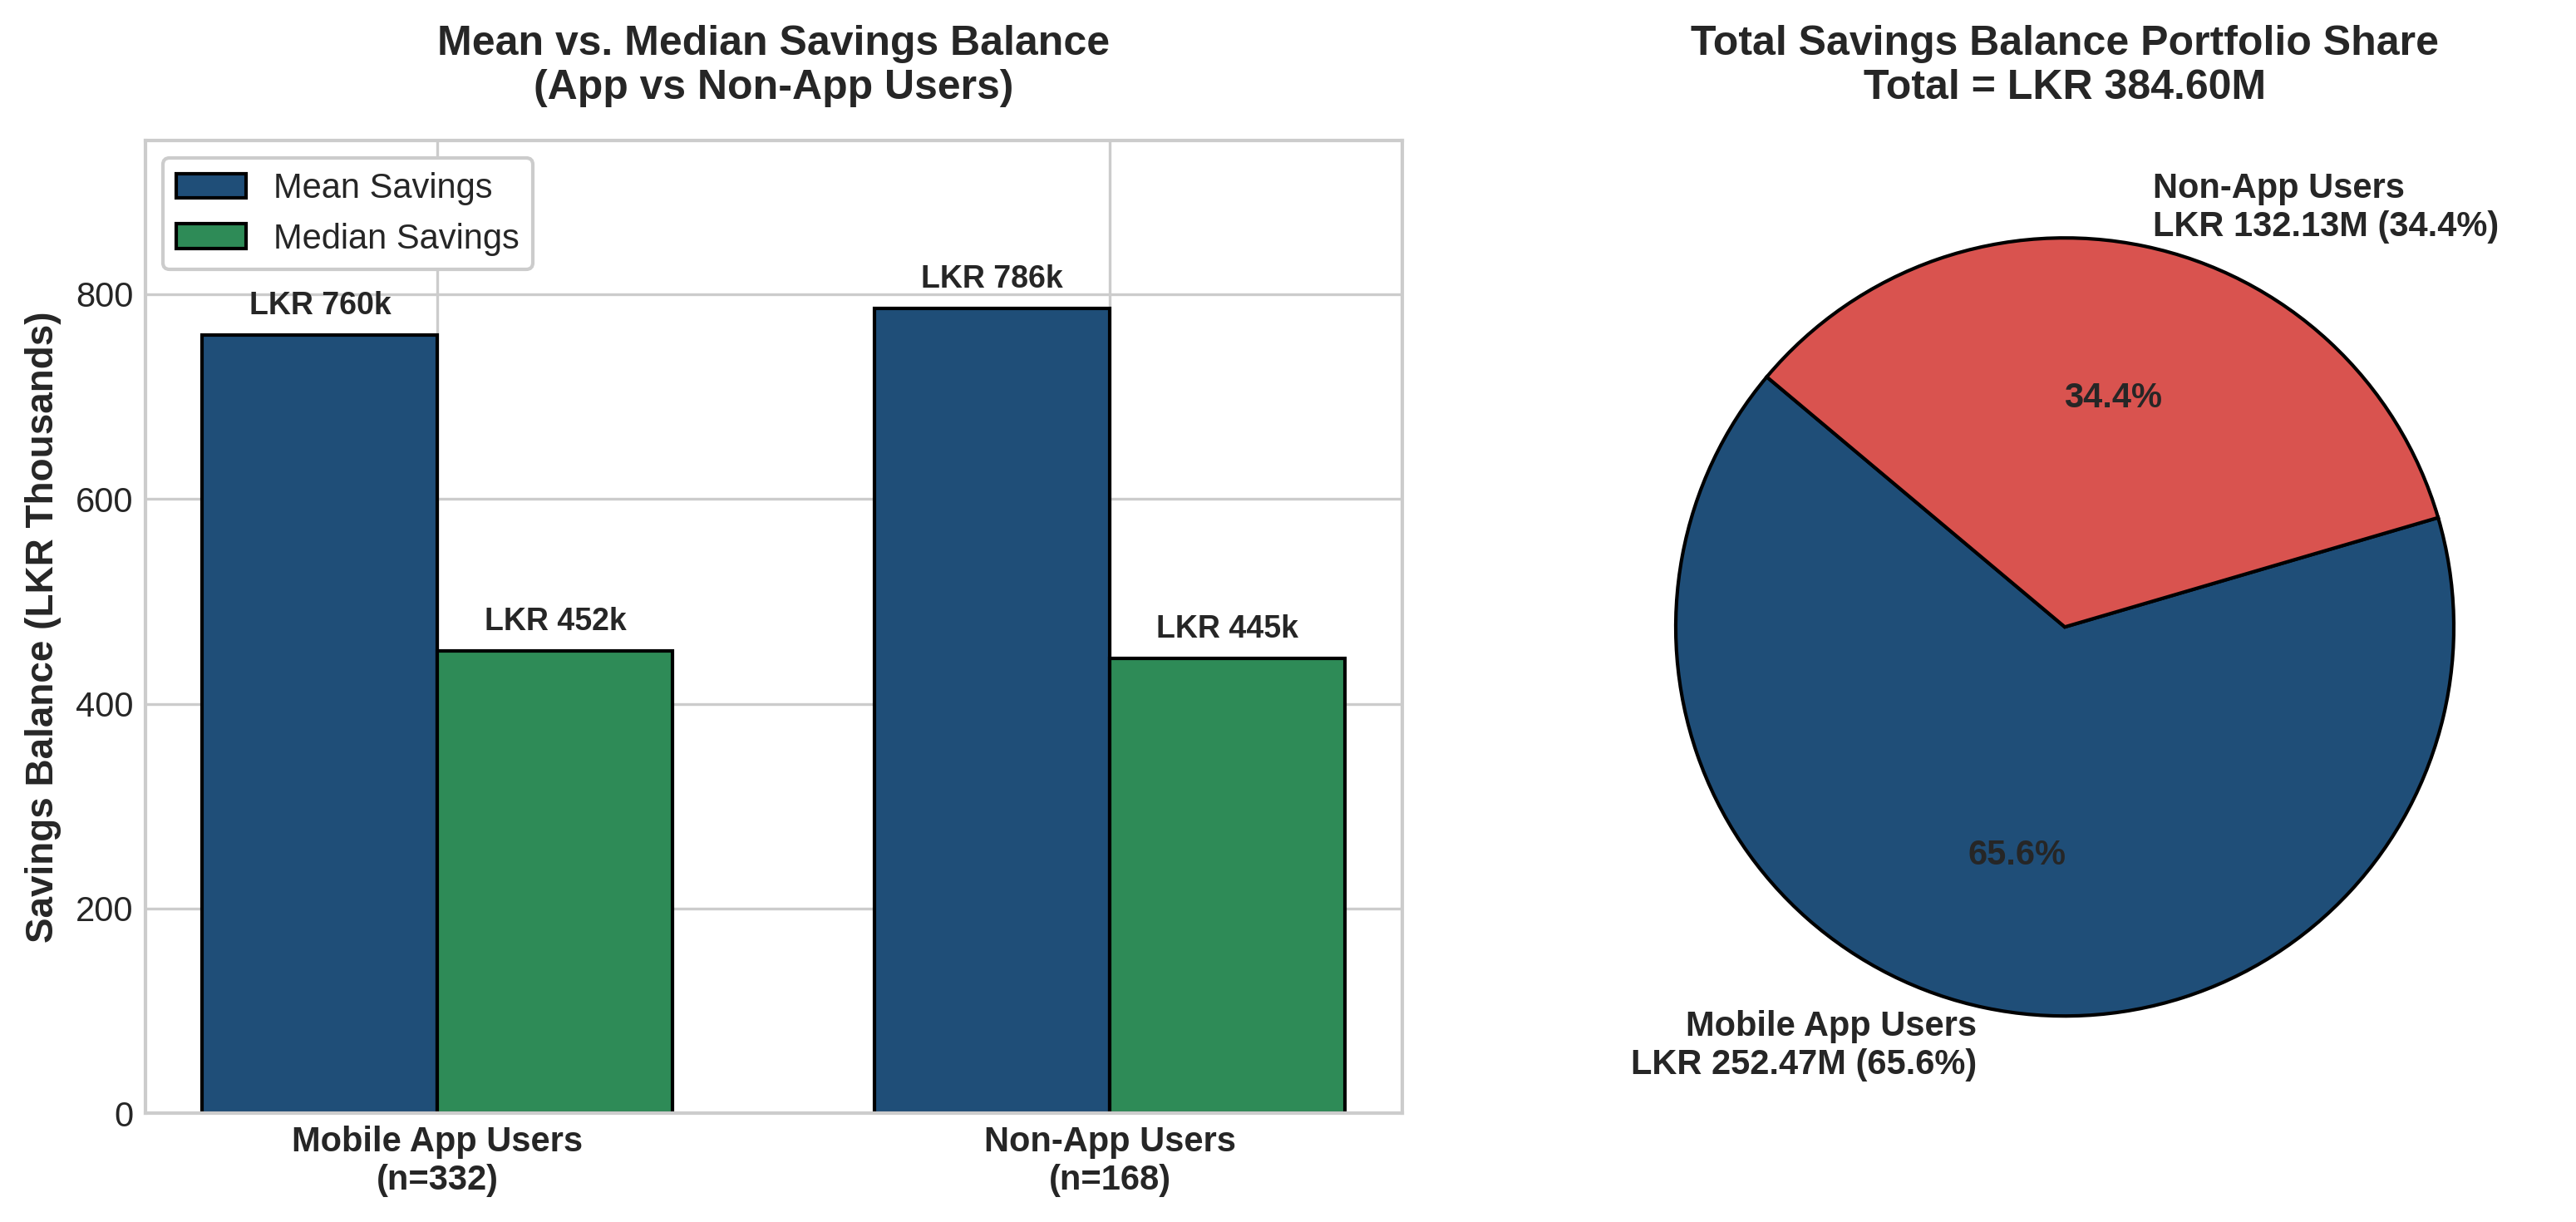

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Set clean aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Create a figure with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), dpi=300)

# --- Subplot 1: Mean vs. Median Savings Bar Chart ---
groups = ['Mobile App Users\n(n=332)', 'Non-App Users\n(n=168)']
means = [760451, 786487]     # In LKR
medians = [451840, 444522]   # In LKR

x = np.arange(len(groups))
width = 0.35

rects1 = ax1.bar(x - width/2, [m/1000 for m in means], width, label='Mean Savings', color='#1f4e78', edgecolor='black')
rects2 = ax1.bar(x + width/2, [m/1000 for m in medians], width, label='Median Savings', color='#2e8b57', edgecolor='black')

ax1.set_ylabel('Savings Balance (LKR Thousands)', fontsize=11, fontweight='bold')
ax1.set_title('Mean vs. Median Savings Balance\n(App vs Non-App Users)', fontsize=12, fontweight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(groups, fontsize=10, fontweight='bold')
ax1.legend(frameon=True, facecolor='white', framealpha=1)
ax1.set_ylim(0, 950)

# Add value annotations on top of bars
for rect in rects1:
    height = rect.get_height()
    ax1.annotate(f'LKR {height:,.0f}k',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    ax1.annotate(f'LKR {height:,.0f}k',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- Subplot 2: Total Portfolio Share Pie Chart ---
totals = [252.47, 132.13] # In LKR Millions
colors_pie = ['#1f4e78', '#d9534f']

ax2.pie(totals,
        labels=['Mobile App Users\nLKR 252.47M (65.6%)', 'Non-App Users\nLKR 132.13M (34.4%)'],
        autopct='%1.1f%%',
        startangle=140,
        colors=colors_pie,
        textprops={'fontsize': 10, 'weight': 'bold'},
        wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax2.set_title('Total Savings Balance Portfolio Share\nTotal = LKR 384.60M', fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

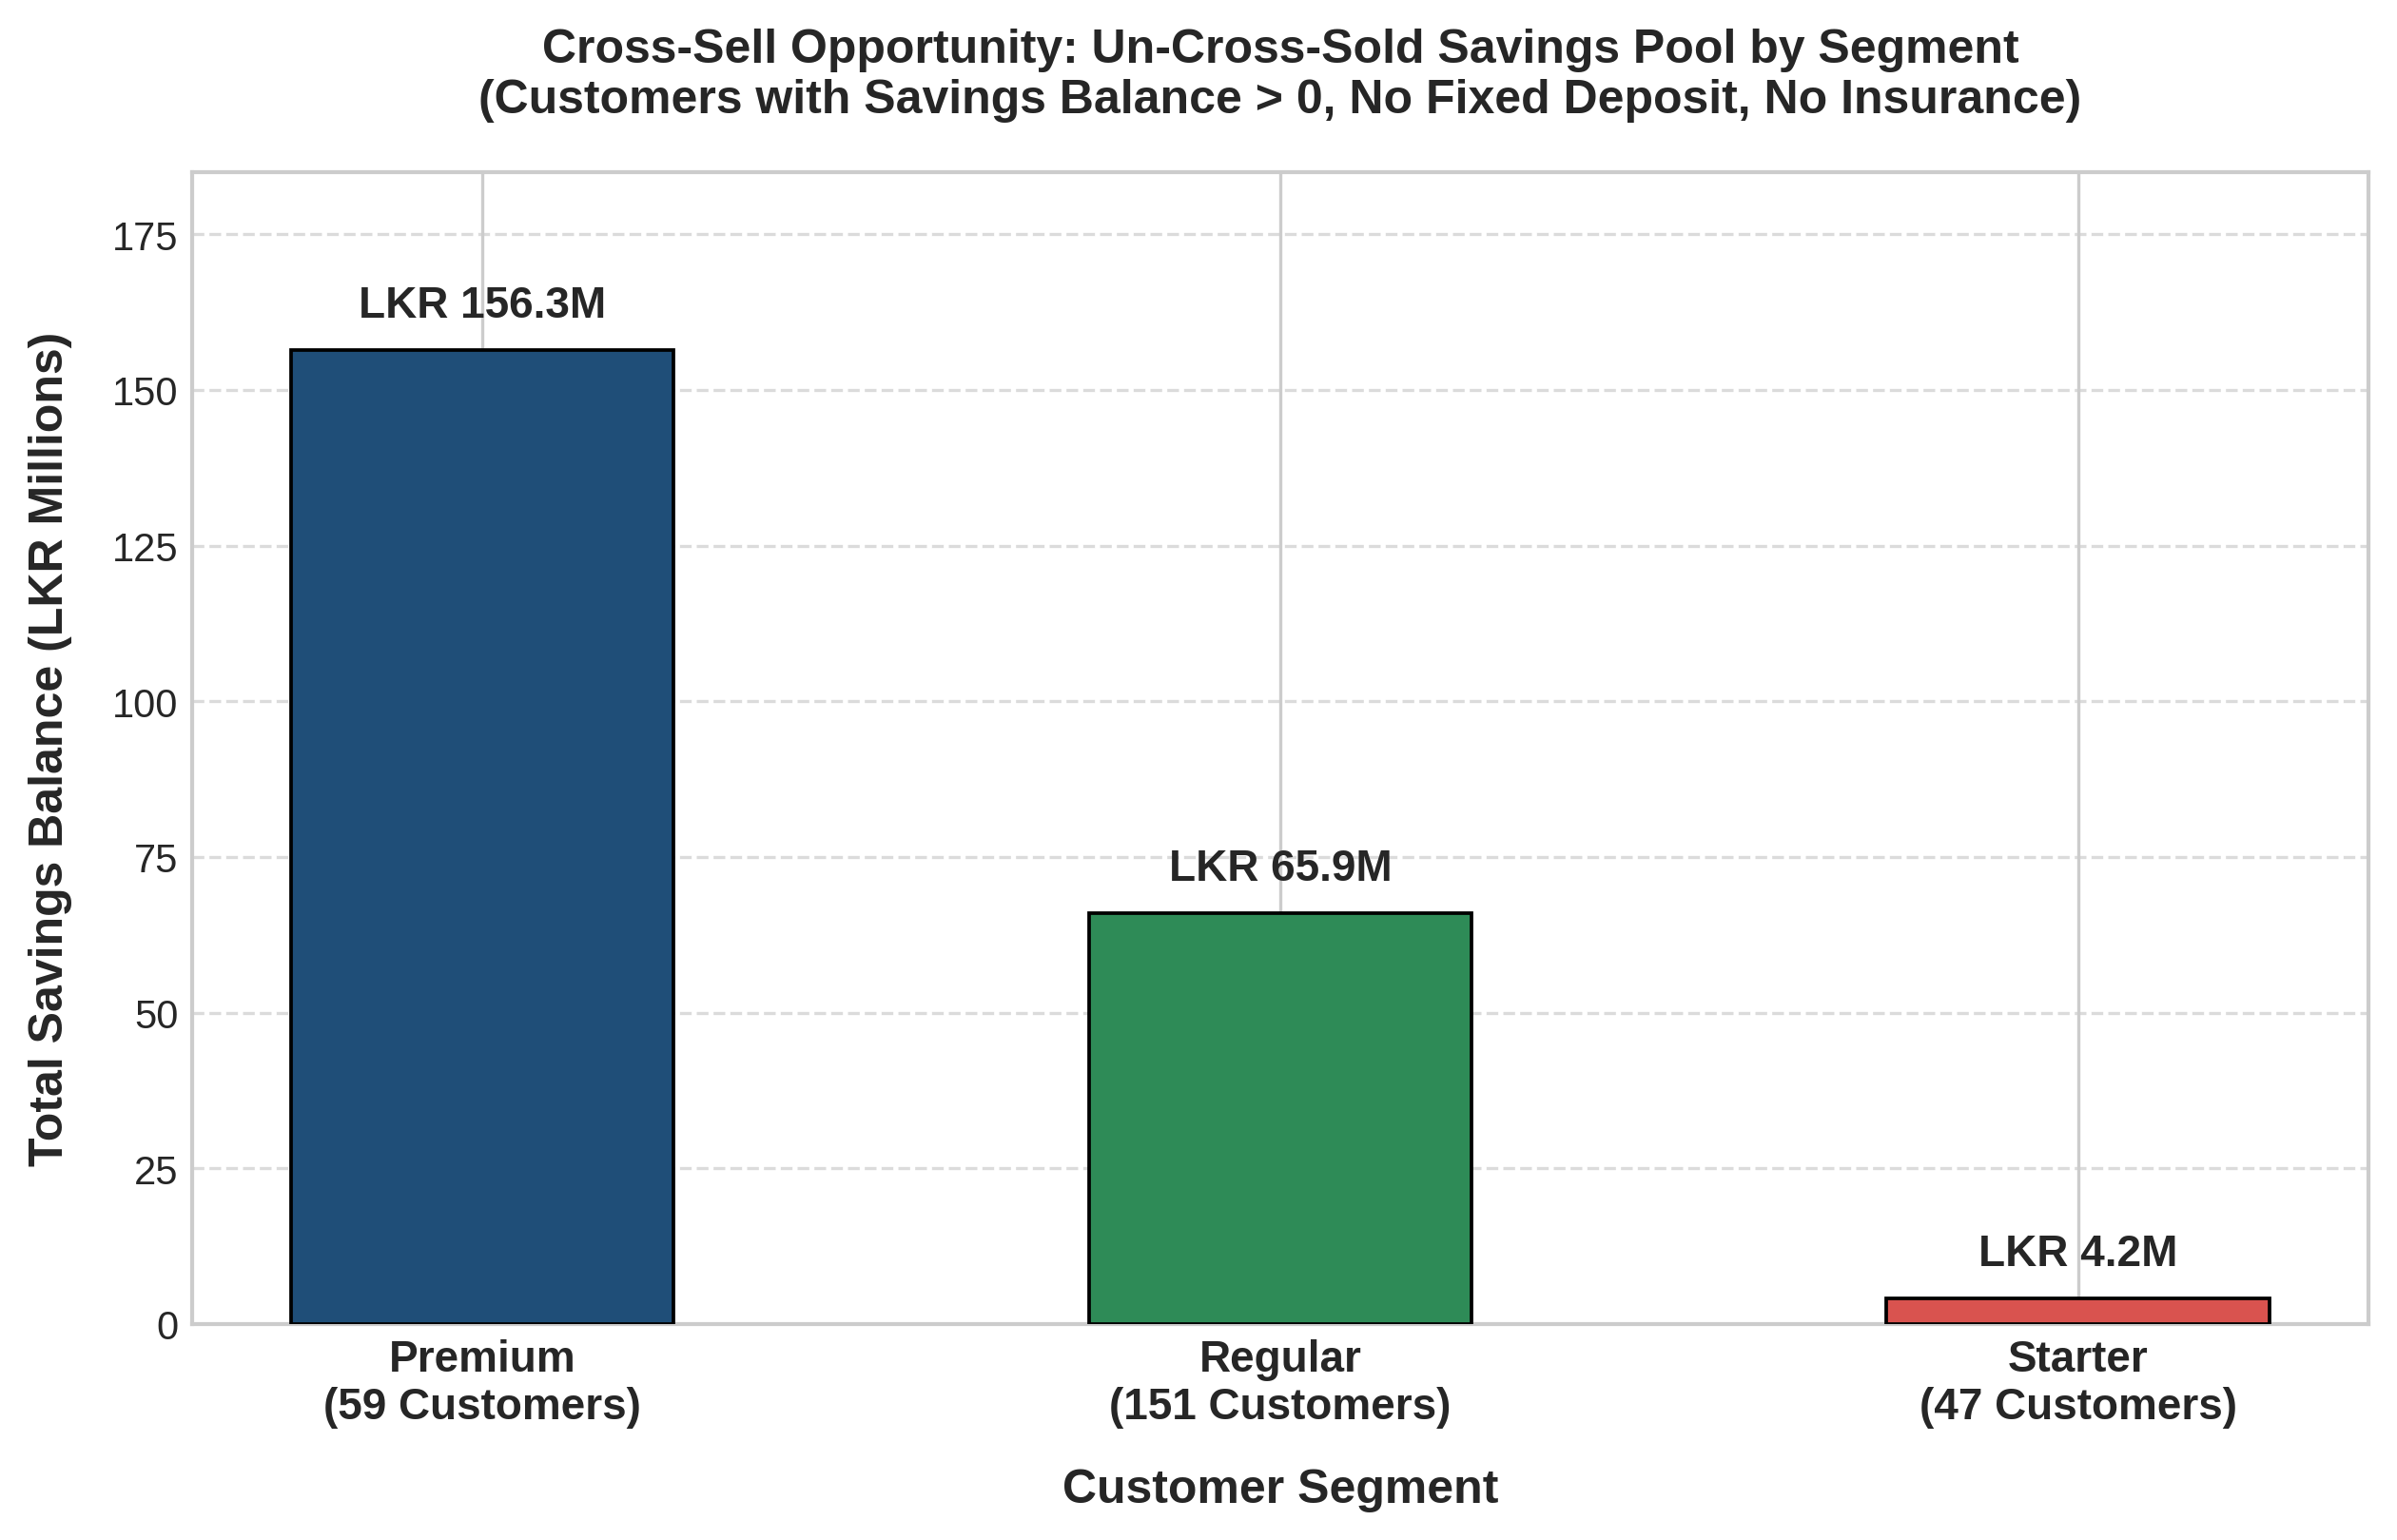

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 2. Filter for cross-sell opportunity: Savings > 0, No Fixed Deposit, and No Insurance
cross_sell_df = df[(df['Savings_Balance'] > 0) &
                  (df['Has_Fixed_Deposit'] == 'No') &
                  (df['Has_Insurance'] == 'No')].copy()

# 3. Aggregate customer counts and total savings balance by Customer Segment
segment_summary = cross_sell_df.groupby('Customer_Segment').agg(
    Customer_Count=('Customer_ID', 'count'),
    Total_Savings_LKR=('Savings_Balance', 'sum')
).reindex(['Premium', 'Regular', 'Starter']).reset_index()

# Convert LKR total savings to Millions
segment_summary['Total_Savings_Millions'] = segment_summary['Total_Savings_LKR'] / 1e6

# 4. Generate Visualization
fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=300)

categories = [f"{row['Customer_Segment']}\n({row['Customer_Count']} Customers)" for _, row in segment_summary.iterrows()]
values = segment_summary['Total_Savings_Millions'].values
colors = ['#1f4e78', '#2e8b57', '#d9534f']  # Color palette for segments

x = np.arange(len(categories))
width = 0.48

# Plot bars with borders
bars = ax.bar(x, values, width=width, color=colors, edgecolor='black', linewidth=0.9, zorder=3)

# Gridlines on Y-axis
ax.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)

# Annotate values above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'LKR {height:.1f}M',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Standard axes formatting
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylabel('Total Savings Balance (LKR Millions)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_xlabel('Customer Segment', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Cross-Sell Opportunity: Un-Cross-Sold Savings Pool by Segment\n(Customers with Savings Balance > 0, No Fixed Deposit, No Insurance)',
             fontsize=12, fontweight='bold', pad=15)

ax.set_ylim(0, 185)

plt.tight_layout()
plt.show()

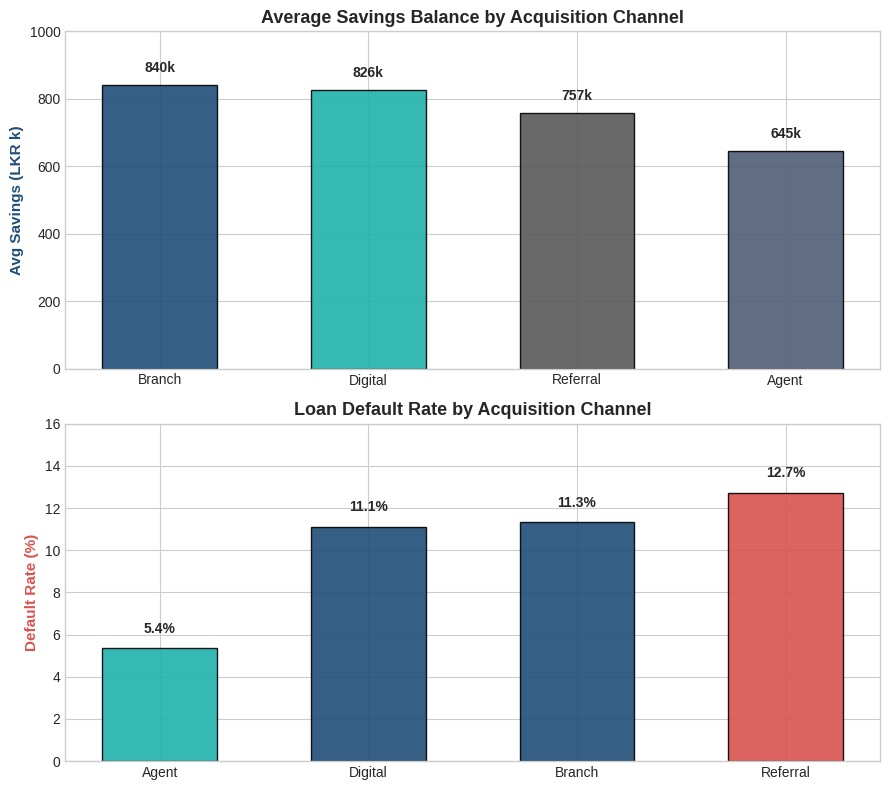

In [48]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd



# 2. Compute Average Savings by Channel (in LKR thousands)
avg_savings = (
    df.groupby('Acquisition_Channel')['Savings_Balance'].mean() / 1e3
).sort_values(ascending=False)

# 3. Compute Default Rate by Channel (% of loans that defaulted)
channel_loans = df[df['Has_Loan'] == 'Yes']
default_counts = (
    channel_loans[channel_loans['Loan_Repayment_Status'] == 'Defaulted']
    .groupby('Acquisition_Channel')
    .size()
)
total_loans = channel_loans.groupby('Acquisition_Channel').size()
default_rates = ((default_counts / total_loans) * 100).sort_values()

# 4. Set up 2-panel figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))

# Top Chart: Average Savings Balance
bars1 = ax1.bar(
    avg_savings.index,
    avg_savings.values,
    color=['#1f4e78', '#20b2aa', '#595959', '#4f5d75'],
    width=0.55,
    edgecolor='black',
    alpha=0.9,
)
ax1.set_title(
    'Average Savings Balance by Acquisition Channel',
    fontsize=13,
    fontweight='bold',
)
ax1.set_ylabel(
    'Avg Savings (LKR k)', fontsize=11, fontweight='bold', color='#1f4e78'
)
ax1.set_ylim(0, 1000)

for bar, val in zip(bars1, avg_savings.values):
  ax1.text(
      bar.get_x() + bar.get_width() / 2.,
      bar.get_height() + 30,
      f'{val:.0f}k',
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
  )

# Bottom Chart: Loan Default Rate
bars2 = ax2.bar(
    default_rates.index,
    default_rates.values,
    color=['#20b2aa', '#1f4e78', '#1f4e78', '#d9534f'],
    width=0.55,
    edgecolor='black',
    alpha=0.9,
)
ax2.set_title(
    'Loan Default Rate by Acquisition Channel', fontsize=13, fontweight='bold'
)
ax2.set_ylabel(
    'Default Rate (%)', fontsize=11, fontweight='bold', color='#d9534f'
)
ax2.set_ylim(0, 16)

for bar, val in zip(bars2, default_rates.values):
  ax2.text(
      bar.get_x() + bar.get_width() / 2.,
      bar.get_height() + 0.6,
      f'{val:.1f}%',
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
  )

plt.tight_layout()
plt.savefig('acquisition_channel_comparison.png', dpi=300)
plt.show()